In [ ]:
from AttackTSFM.utils.utils import set_seed
from AttackTSFM.utils.visualization import plot_results_with_quantile_adv
import torch
from einops import rearrange, repeat
from AttackTSFM.utils.evaluator import Evaluator
from models import TimesFm, Moirai, Chronos, TabPFN, UniTS, TimeMoE
from AttackTSFM.utils.TStransform import TimeSeriesTransform, drift_fn, local_offset_fn
from AttackTSFM.attack import PGD, SimBA, ZOO, ZOOAdam
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

from AttackTSFM.data.data_module import DataModule
from AttackTSFM.data.data_manager import DataManager

set_seed(42)

# Load Model

In [ ]:
def load_dataset(dataset, batch_size, context_length, prediction_length=None):
    data_manager = DataManager(
        dataset = dataset,
        # change your dataset path here
        path = '/home/PATH/TO/DATA/',
        history_length=context_length,
        context_length = context_length,
        prediction_length = prediction_length,
        scaler='standard',
        timeenc=2)

    data_module = DataModule(data_manager=data_manager, batch_size=batch_size, test_batch_size=batch_size, num_workers=8)
    return data_manager, data_module

In [3]:
def load_model(model, model_size, data_manager):
    if model == 'timesfm':
        model = TimesFm(
            context_len=data_manager.context_length,
            input_patch_len=32,
            output_patch_len=128,
            model_size=model_size, # '200m', '500m'
            horizon_len=data_manager.prediction_length
            ).to(device)

    elif model == 'moirai':
        model = Moirai(
            prediction_length=data_manager.prediction_length,
            context_length=data_manager.context_length,
            variate_mode='S',
            patch_size=32,
            model_size=model_size, # 'small', 'base', 'large'
            target_dim=1,
            device=device,
            ).to(device)

    elif model == 'chronos':
        model = Chronos(
            model_size=model_size, # 'tiny', 'mini', 'small', 'base', 'large'
            prediction_length=data_manager.prediction_length,
        )
    elif model == 'tabpfn':
        model = TabPFN()

    elif model == 'units':
        model = UniTS(
            context_length=data_manager.context_length,
            prediction_length=data_manager.prediction_length,
            model_size=model_size, # '32', '128'
            target_dim=data_manager.target_dim,
            device=device,
        ).to(device)
        
    elif model == 'timemoe':
        model = TimeMoE(
        context_length=data_manager.context_length,
        prediction_length=data_manager.prediction_length,
        model_size=model_size) # '50M', '200M'
        
    return model

In [4]:
def get_transformation(a, beta, K, start_step, delta_range=2):
    targeted=True
    if beta != 0:
        transform = TimeSeriesTransform(a=a, c_fn=lambda T: drift_fn(T, beta=beta))
    elif K != 0:
        transform = TimeSeriesTransform(a=a, c_fn=lambda T: local_offset_fn(T, K=K, start_step=start_step, delta_range=delta_range, random_sample=False))
    else:
        transform = TimeSeriesTransform(a=a)

    if a == 1 and K == 0 and beta == 0:
        targeted=False
        
    return transform, targeted

In [5]:
def get_attack(attack, model, targeted, alpha, norm, point_num, num_iterations, q=1, attack_mode='random', attack_basis='point', block_size=None, mask_ratio=0.5):
    # Define Attacks
    if attack == 'simba':
        attacker = SimBA(model, targeted=targeted, mode=attack_mode, basis=attack_basis, block_size=block_size, mask_ratio=mask_ratio)
    elif attack == 'zoo':
        attacker = ZOO(model, alpha=alpha, targeted=targeted, mode=attack_mode, norm=norm, q=q)
    elif attack == 'zoo_adam':
        attacker = ZOOAdam(model, alpha=alpha, targeted=targeted, mode=attack_mode, norm=norm, q=q)
    elif attack == 'pgd':
        attacker = PGD(model, alpha=alpha, targeted=targeted, norm=norm)

    if attack == 'simba':
        max_iters = int(min(point_num, num_iterations))
    else:
        max_iters = num_iterations
    return attacker, max_iters

In [10]:
def run_exp(data_manager, data_module, model, model_size, 
            attack, attack_ratio, epsilon, alpha, num_iterations, q=1, 
            a=1, beta=0, K=0, start_step=0, attack_gt=False, attack_basis='point', attack_mode='random', norm='linf',
            block_size=None, mask_ratio=0.5):
    model = load_model(model, model_size, data_manager)
    evaluator = Evaluator()
    transform, targeted = get_transformation(a, beta, K, start_step)
    point_num = int(attack_ratio * data_manager.context_length)
    attacker, max_iters = get_attack(attack, model, targeted, alpha, norm, point_num, num_iterations, q=q, 
                                     attack_mode=attack_mode, attack_basis=attack_basis, block_size=block_size, mask_ratio=mask_ratio)
    
    input_data, perturbed_input_data = [], []
    pred_target, transformed_target = [], []
    forecasts_list, forecasts_list_perturbed = [], []
    quantile_forecasts_list, quantile_forecasts_list_perturbed = [], []

    for i, batch in enumerate(data_module.test_dataloader()):
        # [b l k] or [b l]
        past_tensor = batch['past_target_cdf'].to(device)  # historical data
        actuals_tensor = batch['future_target_cdf'].to(device)  # groundtruh
        past_datastamps = batch['past_time_feat']
        future_datastamps = batch['future_time_feat']
        
        if batch['past_target_cdf'].ndim == 3:
            past_tensor = rearrange(past_tensor, 'b l k -> (b k) l')
            actuals_tensor = rearrange(actuals_tensor, 'b l k -> (b k) l')
            past_datastamps = repeat(past_datastamps, 'b l 1 -> (b k) l', k=data_manager.target_dim)
            future_datastamps = repeat(future_datastamps, 'b l 1 -> (b k) l', k=data_manager.target_dim)
            
        
        past_tensor = past_tensor[:, -data_manager.context_length:]
        past_datastamps = past_datastamps[:, -data_manager.context_length:]
        
        # clean forecasts
        with torch.no_grad():
            # [b k l q]
            forecasts, quantile_forecasts = model(past_tensor, past_datastamps=past_datastamps, future_datastamps=future_datastamps)
        
        if attack_gt:
            attack_target = actuals_tensor.clone()
        else:
            attack_target = forecasts.detach().clone() # attack the forecasts

        transformed_target_tensor = transform(attack_target)
        
        if point_num > 0:
            perturbed_past_tensor = attacker.attack_batch(past_tensor, transformed_target_tensor, n_dims=point_num, max_iters=max_iters, \
                epsilon=epsilon, past_datastamps=past_datastamps, future_datastamps=future_datastamps)
        else:
            perturbed_past_tensor = past_tensor.clone()
        
        forecasts_perturbed, quantile_forecasts_perturbed = model(perturbed_past_tensor, past_datastamps=past_datastamps, future_datastamps=future_datastamps)

        # Detach and move tensors to CPU
        actuals_tensor, past_tensor, forecasts, quantile_forecasts, forecasts_perturbed, quantile_forecasts_perturbed, perturbed_past_tensor, transformed_target_tensor = [
        t.cpu().detach() for t in [actuals_tensor, past_tensor, forecasts, quantile_forecasts, forecasts_perturbed, quantile_forecasts_perturbed, perturbed_past_tensor, transformed_target_tensor]
        ]
        
        past_tensor = rearrange(past_tensor, '(b k) l -> b k l', k=data_manager.target_dim)
        perturbed_past_tensor = rearrange(perturbed_past_tensor, '(b k) l -> b k l', k=data_manager.target_dim)
        actuals_tensor = rearrange(actuals_tensor, '(b k) l -> b k l', k=data_manager.target_dim)
        forecasts = rearrange(forecasts, '(b k) l -> b k l', k=data_manager.target_dim)
        forecasts_perturbed = rearrange(forecasts_perturbed, '(b k) l -> b k l', k=data_manager.target_dim)
        quantile_forecasts = rearrange(quantile_forecasts, '(b k) l q -> b k l q', k=data_manager.target_dim)
        quantile_forecasts_perturbed = rearrange(quantile_forecasts_perturbed, '(b k) l q -> b k l q', k=data_manager.target_dim)
        transformed_target_tensor = rearrange(transformed_target_tensor, '(b k) l -> b k l', k=data_manager.target_dim)
        
        input_data.append(past_tensor)
        perturbed_input_data.append(perturbed_past_tensor)
        pred_target.append(actuals_tensor)
        transformed_target.append(transformed_target_tensor)
        forecasts_list.append(forecasts)
        forecasts_list_perturbed.append(forecasts_perturbed)
        quantile_forecasts_list.append(quantile_forecasts)
        quantile_forecasts_list_perturbed.append(quantile_forecasts_perturbed)

    results = {
        "input": torch.cat(input_data, dim=0),
        "perturbed_input": torch.cat(perturbed_input_data, dim=0),
        "pred_target": torch.cat(pred_target, dim=0),
        "forecasts": torch.cat(forecasts_list, dim=0),
        "forecasts_perturbed": torch.cat(forecasts_list_perturbed, dim=0),
        "quantile_forecasts": torch.cat(quantile_forecasts_list, dim=0),
        "quantile_forecasts_perturbed": torch.cat(quantile_forecasts_list_perturbed, dim=0),
        "transformed_target": torch.cat(transformed_target, dim=0),
    }

    clean_metrics_gt = evaluator(results['pred_target'], results['quantile_forecasts'], results['input'], freq=data_manager.freq)
    perturbed_metrics_gt = evaluator(results['pred_target'], results['quantile_forecasts_perturbed'], results['input'], freq=data_manager.freq)

    clean_metrics_transformed = evaluator(results['transformed_target'], results['quantile_forecasts'], results['input'], freq=data_manager.freq)
    perturbed_metrics_transformed = evaluator(results['transformed_target'], results['quantile_forecasts_perturbed'], results['input'], freq=data_manager.freq)

    # print(f"Clean ND Loss (Ground Truth): {clean_metrics_gt['ND']}")
    # print(f"Clean NRMSE Loss (Ground Truth): {clean_metrics_gt['NRMSE']}")
    # print(f"Clean CRPS Loss (Ground Truth): {clean_metrics_gt['CRPS']}")

    # print(f"Perturbed ND Loss (Ground Truth): {perturbed_metrics_gt['ND']}")
    # print(f"Perturbed NRMSE Loss (Ground Truth): {perturbed_metrics_gt['NRMSE']}")
    # print(f"Perturbed CRPS Loss (Ground Truth): {perturbed_metrics_gt['CRPS']}")


    # print(f"Clean ND Loss (Targeted): {clean_metrics_transformed['ND']}")
    # print(f"Clean NRMSE Loss (Targeted): {clean_metrics_transformed['NRMSE']}")
    # print(f"Clean CRPS Loss (Targeted): {clean_metrics_transformed['CRPS']}")

    # print(f"Perturbed ND Loss (Targeted): {perturbed_metrics_transformed['ND']}")
    # print(f"Perturbed NRMSE Loss (Targeted): {perturbed_metrics_transformed['NRMSE']}")
    # print(f"Perturbed CRPS Loss (Targeted): {perturbed_metrics_transformed['CRPS']}")
    
    return results, clean_metrics_gt, perturbed_metrics_gt, clean_metrics_transformed, perturbed_metrics_transformed

# Configuration

In [15]:
context_length = 256
batch_size = 32
dataset = 'gift/ett1/H/medium'
data_manager, data_module = load_dataset(dataset, batch_size, context_length)

model='timesfm'
model_size='200m'

attack='pgd'
alpha=0.05
epsilon=0.5
attack_ratio=1
num_iterations=500

BETA version: generating test datasets for gift eval, should contain 4 windows.


# Attack TSFMs

## Flip

In [ ]:
a=-1
b=0
K=0
start_step=0
attack_ratio=1

results, clean_metrics_gt, perturbed_metrics_gt, clean_metrics_transformed, perturbed_metrics_transformed = run_exp(
    data_manager, data_module, model, model_size, 
    attack, attack_ratio, epsilon, alpha, num_iterations, 
    a=a, beta=b, K=0, start_step=0)

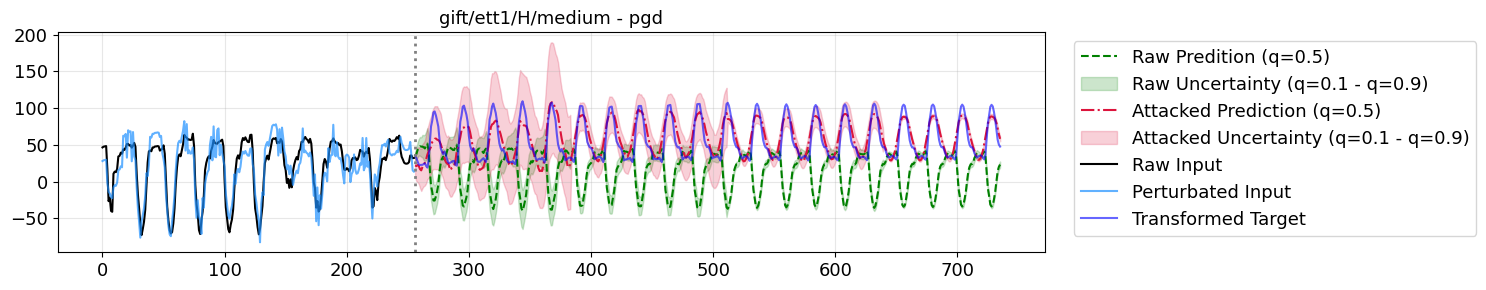

In [27]:
batch_idx = 0
var_idx = 0

plot_results_with_quantile_adv(
    input_data = results['input'][batch_idx,var_idx], 
    perturbed_input_data = results['perturbed_input'][batch_idx,var_idx], 
    # target_data = results['pred_target'][batch_idx,var_idx],
    forecast_df = results['quantile_forecasts'][batch_idx, var_idx], 
    forecast_df_perturbed = results['quantile_forecasts_perturbed'][batch_idx, var_idx],
    transformed_target_data = results['transformed_target'][batch_idx,var_idx], 
    title = f'{dataset} - {attack}',
    figsize=(15, 3),
    fontsize=13)

## Drift

In [ ]:
a=1
b=0.1
K=0
start_step=0

results, clean_metrics_gt, perturbed_metrics_gt, clean_metrics_transformed, perturbed_metrics_transformed = run_exp(
    data_manager, data_module, model, model_size, 
    attack, attack_ratio, epsilon, alpha, num_iterations, 
    a=a, beta=b, K=0, start_step=0)

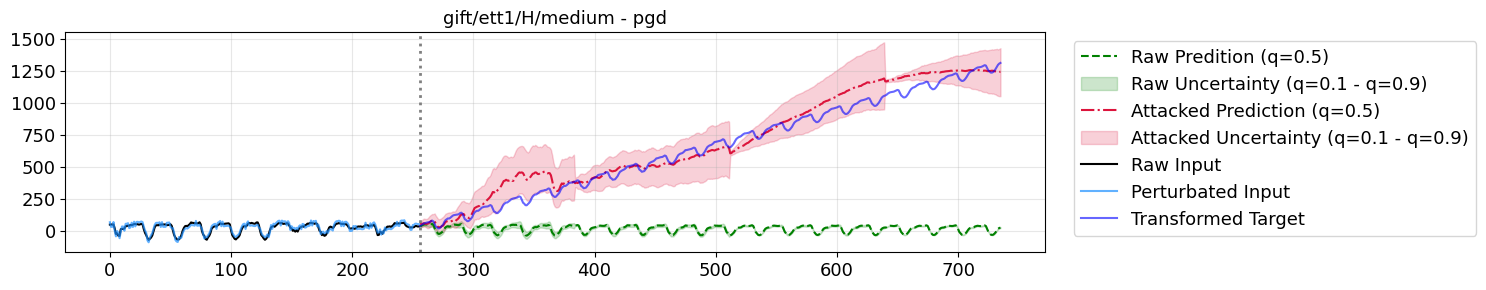

In [20]:
batch_idx = 0
var_idx = 0

plot_results_with_quantile_adv(
    input_data = results['input'][batch_idx,var_idx], 
    perturbed_input_data = results['perturbed_input'][batch_idx,var_idx], 
    # target_data = results['pred_target'][batch_idx,var_idx],
    forecast_df = results['quantile_forecasts'][batch_idx, var_idx], 
    forecast_df_perturbed = results['quantile_forecasts_perturbed'][batch_idx, var_idx],
    transformed_target_data = results['transformed_target'][batch_idx,var_idx], 
    title = f'{dataset} - {attack}',
    figsize=(15, 3),
    fontsize=13)

## Local Offset

In [ ]:
a=1
b=0
K=0.25
start_step=0.1

results, clean_metrics_gt, perturbed_metrics_gt, clean_metrics_transformed, perturbed_metrics_transformed = run_exp(
    data_manager, data_module, model, model_size, 
    attack, attack_ratio, epsilon, alpha, num_iterations, 
    a=a, beta=b, K=K, start_step=start_step)

Clean ND Loss (Ground Truth): 0.3995818758743971
Perturbed ND Loss (Ground Truth): 0.46130974008669945


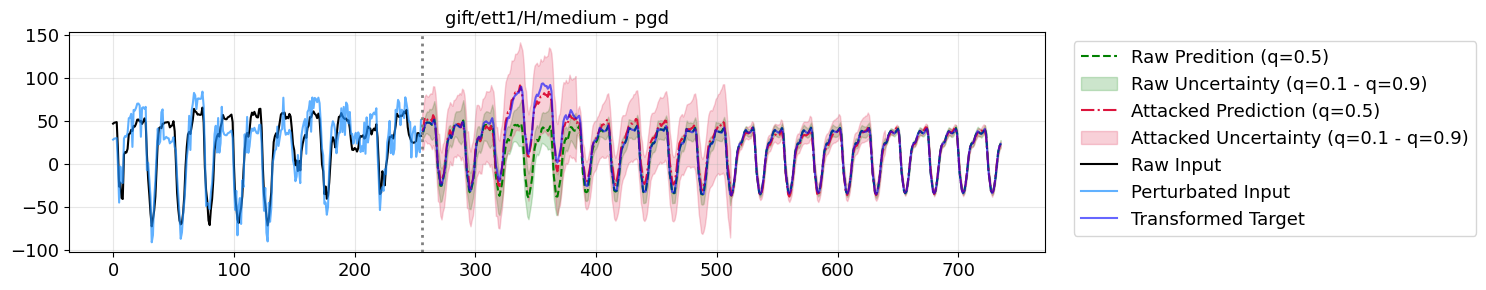

In [29]:
batch_idx = 0
var_idx = 0

print(f"Clean ND Loss (Ground Truth): {clean_metrics_gt['ND']}")
print(f"Perturbed ND Loss (Ground Truth): {perturbed_metrics_gt['ND']}")

plot_results_with_quantile_adv(
    input_data = results['input'][batch_idx,var_idx], 
    perturbed_input_data = results['perturbed_input'][batch_idx,var_idx], 
    # target_data = results['pred_target'][batch_idx,var_idx],
    forecast_df = results['quantile_forecasts'][batch_idx, var_idx], 
    forecast_df_perturbed = results['quantile_forecasts_perturbed'][batch_idx, var_idx],
    transformed_target_data = results['transformed_target'][batch_idx,var_idx], 
    title = f'{dataset} - {attack}',
    figsize=(15, 3),
    fontsize=13)